In [1]:
# Import all required dependencies and data

!pip install dipy
!pip install igraph
!pip install bctpy
!pip install gdown

import pandas as pd
import numpy as np
import dipy
import nibabel as nib
import matplotlib.pyplot as plt
import networkx as nx
import bct
import igraph as ig
from tqdm import tqdm
import seaborn as sns
from google.colab import drive
import gdown

#drive.mount('/content/drive', force_remount=True)
#data_folder = '/content/drive/My Drive/Brain_Netwroks_Final_Project/final_assignment_data'

FOLDER_ID = "1QSDOBbVmwJAH_4sV0sHEnz8s3lDk7x5N"

# download the whole folder into ./data
gdown.download_folder(
    id=FOLDER_ID,
    output="data",
    quiet=False,
    use_cookies=False
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 63.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.2/45.2 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.1/85.1 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 64.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.4/110.4 kB 6.7 MB/s eta 0:00:00


Retrieving folder contents


Processing file 1_Zf8dmg1HLT_6oEv1Tj6XsH4rIJEmFJD func_labels.npy
Processing file 1JLVsuDy3j6k3fGv9AVNFLd5t9xNCWa7r functional_mat.npy
Processing file 1IpCrSIdEHB5WwNAc5PkTgVyP5L9xgPni struct_labels.npy
Processing file 1VsJCOYWZBPS0qrh2GmgCi6CA-y_WQMIn structural_matrix.npy


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1_Zf8dmg1HLT_6oEv1Tj6XsH4rIJEmFJD
To: /content/data/func_labels.npy
100%|██████████| 14.7k/14.7k [00:00<00:00, 21.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1JLVsuDy3j6k3fGv9AVNFLd5t9xNCWa7r
To: /content/data/functional_mat.npy
100%|██████████| 31.9k/31.9k [00:00<00:00, 29.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1IpCrSIdEHB5WwNAc5PkTgVyP5L9xgPni
To: /content/data/struct_labels.npy
100%|██████████| 2.10k/2.10k [00:00<00:00, 4.49MB/s]
Downloading...
From: https://drive.google.com/uc?id=1VsJCOYWZBPS0qrh2GmgCi6CA-y_WQMIn
To: /content/data/structural_matrix.npy
100%|██████████| 484k/484k [00:00<00:00, 8.91MB/s]
Download completed


['data/func_labels.npy',
 'data/functional_mat.npy',
 'data/struct_labels.npy',
 'data/structural_matrix.npy']

# Load connectome data
### for Q1 and Q2

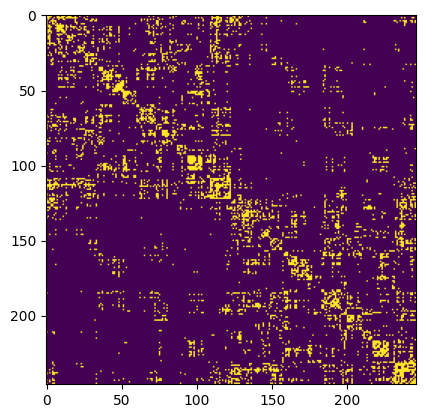

In [2]:
#matrix = np.load(f'{data_folder}/structural_matrix.npy', allow_pickle=True)
#labels = np.load(f'{data_folder}/struct_labels.npy', allow_pickle=True)

matrix = np.load("data/structural_matrix.npy")
labels = np.load("data/struct_labels.npy")

# assuming the values of the structural matrix are the amount of connections between each two nodes, we'll invert it (1/matrix)

# make the labels the index of the matrix
df = pd.DataFrame(matrix, index=labels, columns=labels)

safe_weights = np.where(matrix > 0, matrix, np.inf)
inv_mat = np.where(safe_weights != np.inf, 1 / safe_weights, 0)

plt.imshow(inv_mat > 0)

graph = nx.from_numpy_array(inv_mat)
nodes = graph.nodes
edges = graph.edges

# Question 1

Weighted Local Efficiency: Avg = 0.23958082175274545, Max = 0.645681252283458, Min = 0.08336814725481288


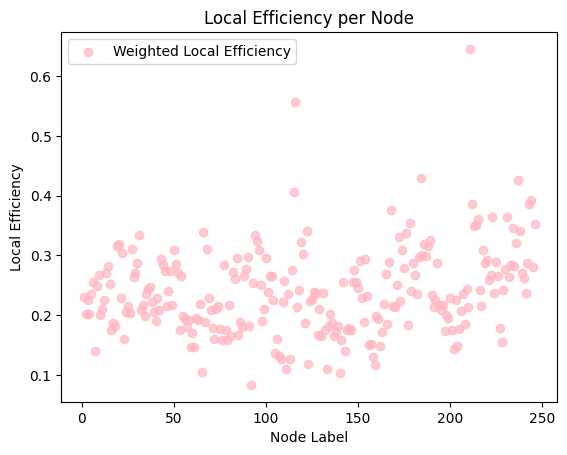

In [3]:
# calculate the local efficiency
# weighted local efficiency
wei_local_efficiency = bct.efficiency_wei(inv_mat, local=True)

# average of local effieciency of each node
wei_avg = np.mean(wei_local_efficiency)
wei_max = np.max(wei_local_efficiency)
wei_min = np.min(wei_local_efficiency)
print(f"Weighted Local Efficiency: Avg = {wei_avg}, Max = {wei_max}, Min = {wei_min}")

# create a Scatter Plot (Local Efficiency vs. Node Degree/Strength):
plt.scatter(
    labels,
    wei_local_efficiency,
    label="Weighted Local Efficiency",
    alpha=0.7,
    color = 'lightpink'
)

plt.xlabel("Node Label")
plt.ylabel("Local Efficiency")
plt.title("Local Efficiency per Node")
plt.legend()
plt.show()


Binary Local Efficiency: Avg = 0.6848155420117147, Max = 1.0, Min = 0.32222222222222224


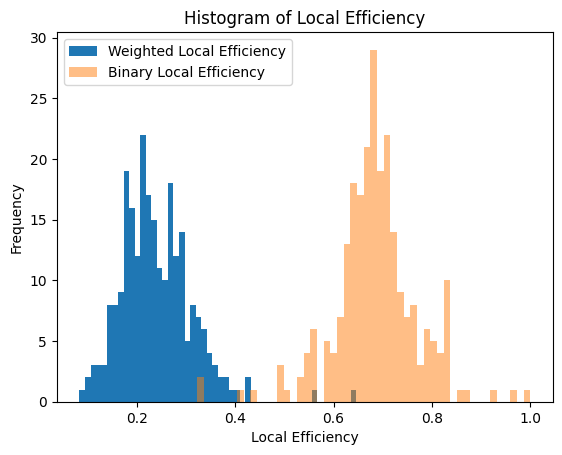

In [4]:
# binary local efficiency
bin_local_efficiency = bct.efficiency_bin(inv_mat, local=True)
bin_avg = np.mean(bin_local_efficiency)
bin_max = np.max(bin_local_efficiency)
bin_min = np.min(bin_local_efficiency)
print(f"Binary Local Efficiency: Avg = {bin_avg}, Max = {bin_max}, Min = {bin_min}")

# create a histogram of the local efficiency and the binary local efficiency and show in the same figure

plt.hist(wei_local_efficiency, bins=50)
plt.hist(bin_local_efficiency, bins=50, alpha=0.5)
plt.legend(["Weighted Local Efficiency", "Binary Local Efficiency"])
plt.xlabel("Local Efficiency")
plt.ylabel("Frequency")
plt.title("Histogram of Local Efficiency")
plt.show()


# Question 2

/usr/local/lib/python3.11/dist-packages/bct/algorithms/core.py:615: RuntimeWarning: invalid value encountered in scalar divide
  Rw[k] = Wr / np.sum(wrank_r)


Generating 5 randomized weighted networks...


/usr/local/lib/python3.11/dist-packages/bct/algorithms/core.py:566: RuntimeWarning: invalid value encountered in scalar divide
  Rw[k] = Wr / np.sum(wrank_r)
/tmp/ipython-input-5-4261609051.py:37: RuntimeWarning: Mean of empty slice
  phi_k_values_random_avg = np.nanmean(all_random_phi_k_values_array, axis=0)


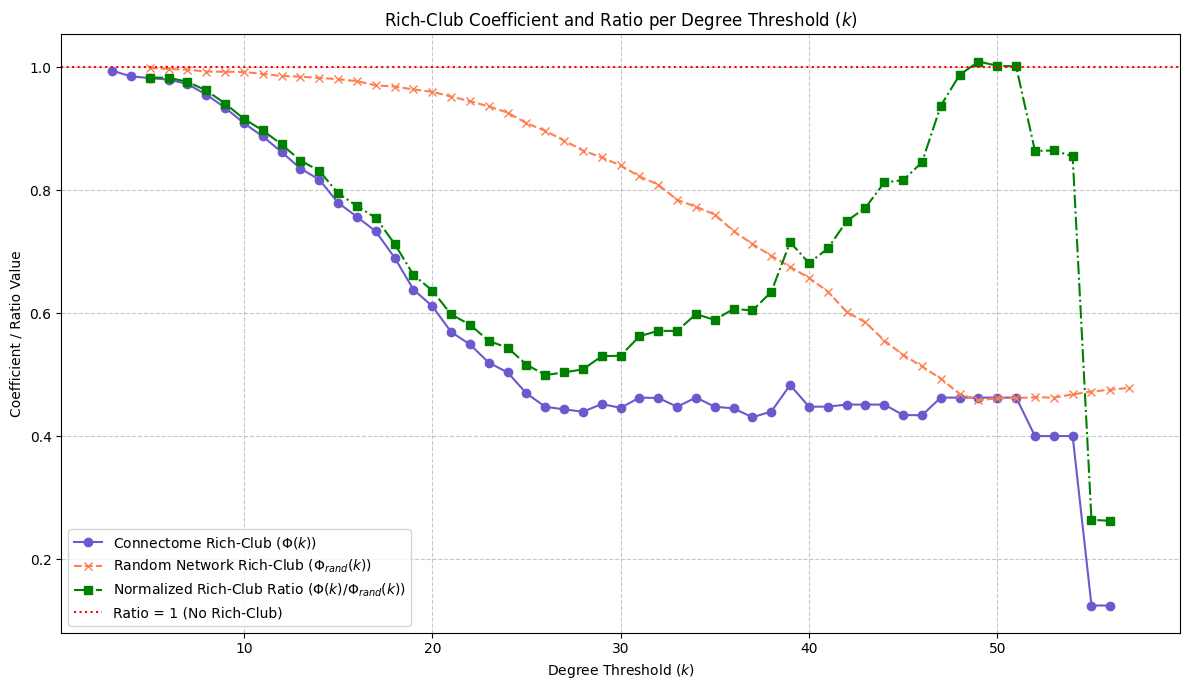


--- Explanation for Rich-Club Range ---
The rich-club phenomenon (ratio > 1.0) is observed approximately from k = 49 to k = 51.
This range indicates that nodes with degrees within this threshold are more densely interconnected among themselves than expected by chance in a similarly structured random network.


In [5]:
# --- Calculate rich-club coefficients for the original network ---
phi_k_values_bct = bct.rich_club_wu(inv_mat)

# Determine the target length for all rich-club coefficient arrays
max_k_len_original = len(phi_k_values_bct)

# --- Generate randomized null model networks (weighted, preserving strength sequence) ---
num_random_networks = 5
all_random_phi_k_values = []

print(f"Generating {num_random_networks} randomized weighted networks...")
for i in range(num_random_networks):
    random_graph, _ = bct.randmio_dir(inv_mat, 100)

    # Calculate weighted rich-club for the randomized graph
    phi_k_random_single = bct.rich_club_wd(random_graph)

    # Pad/truncate to ensure uniform length for numpy array conversion
    if len(phi_k_random_single) < max_k_len_original:
        padded_phi_k = np.pad(
            phi_k_random_single,
            (0, max_k_len_original - len(phi_k_random_single)),
            mode="constant",
            constant_values=np.nan,
        )
    elif len(phi_k_random_single) > max_k_len_original:
        padded_phi_k = phi_k_random_single[:max_k_len_original]
    else:
        padded_phi_k = phi_k_random_single

    all_random_phi_k_values.append(padded_phi_k)

# Convert list of uniform-length arrays to 2D NumPy array
all_random_phi_k_values_array = np.array(all_random_phi_k_values)

# Calculate the average rich-club coefficient across all randomized networks, ignoring NaNs
phi_k_values_random_avg = np.nanmean(all_random_phi_k_values_array, axis=0)

# --- Prepare k values and handle potential length mismatches (now mostly for robustness) ---
k_values_bct = np.arange(0, max_k_len_original)

min_len = min(len(phi_k_values_bct), len(phi_k_values_random_avg))
phi_k_values_bct = phi_k_values_bct[:min_len]
phi_k_values_random_avg = phi_k_values_random_avg[:min_len]
k_values_bct = k_values_bct[:min_len]  # Adjust k_values array as well

# --- Calculate the normalized rich-club coefficient (ratio) ---
rich_club_ratio = np.divide(
    phi_k_values_bct,
    phi_k_values_random_avg,
    out=np.zeros_like(phi_k_values_bct, dtype=float),
    where=phi_k_values_random_avg != 0,
)

# --- Plotting the rich-club coefficients and their ratio ---
plt.figure(figsize=(12, 7))

plt.plot(
    k_values_bct,
    phi_k_values_bct,
    marker="o",
    linestyle="-",
    color="slateblue",
    label="Connectome Rich-Club ($\Phi(k)$)",
)
plt.plot(
    k_values_bct,
    phi_k_values_random_avg,
    marker="x",
    linestyle="--",
    color="coral",
    label="Random Network Rich-Club ($\Phi_{rand}(k)$)",
)
plt.plot(
    k_values_bct,
    rich_club_ratio,
    marker="s",
    linestyle="-.",
    color="green",
    label="Normalized Rich-Club Ratio ($\Phi(k) / \Phi_{rand}(k)$)",
)

# add a horizontal line at y=1 for reference
plt.axhline(y=1, color="red", linestyle=":", label="Ratio = 1 (No Rich-Club)")

plt.title("Rich-Club Coefficient and Ratio per Degree Threshold ($k$)")
plt.xlabel("Degree Threshold ($k$)")
plt.ylabel("Coefficient / Ratio Value")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# --- Explanation for Rich-Club Range ---
print("\n--- Explanation for Rich-Club Range ---")
# Find the range where the ratio is significantly greater than 1
significant_k_indices = np.where(rich_club_ratio > 1)[0]

if len(significant_k_indices) > 0:
    start_k = k_values_bct[significant_k_indices[0]]
    end_k = k_values_bct[significant_k_indices[-1]]
    print(
        f"The rich-club phenomenon (ratio > 1.0) is observed approximately from k = {start_k} to k = {end_k}."
    )
    print(
        "This range indicates that nodes with degrees within this threshold are more densely interconnected among themselves than expected by chance in a similarly structured random network."
    )
    # You can add more nuanced interpretation here based on the shape of the curve, e.g.,
    # where the peak is, how steeply it rises/falls.
else:
    print(
        "No significant rich-club phenomenon (ratio > 1.0) was observed in this network."
    )

# Question 3

Key steps performed during small-woprld analysis are:

1. Normalization weights for weighted analysis to [0, 1] range.
2. Estimation of metrics for the original graph (binary or weighted).
3. Constructing multiple random and lattice graphs with the same node/edge count.
4. Comparison of the real graph’s metrics to those of the synthetic graphs.
5. Compute and return sigma and omega metrics.

Indices used are:

1. Sigma small-world index

$$
\sigma = \frac{C / C_{\text{rand}}}{L / L_{\text{rand}}}
$$

2. Omega small-world index

$$
\omega = \frac{L_{\text{rand}}}{L} - \frac{C}{C_{\text{latt}}}
$$

3. Weighted indices are conputed using weighted clustering coefficient defined as

$$
C_i^w = \frac{1}{k_i (k_i - 1)} \sum_{j,k} \left( w_{ij} \cdot w_{ik} \cdot w_{jk} \right)^{1/3}
$$

In [6]:
def compute_weighted_clustering(matrix: np.ndarray) -> float:
    '''Compute the average weighted clustering coefficient using the Onnela et al. (2005) definition.

    C_i^w = (1 / (k_i * (k_i - 1))) * sum_{j,k} (w_ij * w_ik * w_jk)^(1/3)
    where weights are normalized by the maximum weight in the network.

    Args:
        matrix (np.ndarray): Symmetric adjacency matrix of shape (N, N) with non-negative weights.

    Returns:
        float: The average weighted clustering coefficient over all nodes.
    '''

    matrix = matrix.copy()
    np.fill_diagonal(matrix, 0) # Remove self-loops

    # Normalize weights by the maximum weight in the network
    max_weight = np.max(matrix)
    if max_weight <= 0:
        return 0.0
    matrix = matrix / max_weight

    N = matrix.shape[0]

    Cw = np.zeros(N)

    for i in range(N):
        neighbors = np.nonzero(matrix[i])[0]
        k_i = len(neighbors)
        if k_i < 2:
            continue

        s = 0.0
        # sum over all unordered pairs of neighbors
        for idx_j in range(k_i):
            j = neighbors[idx_j]
            for idx_k in range(idx_j + 1, k_i):
                k = neighbors[idx_k]
                w_ij = matrix[i, j]
                w_ik = matrix[i, k]
                w_jk = matrix[j, k]
                if w_jk > 0:
                    s += (w_ij * w_ik * w_jk) ** (1/3)

        Cw[i] = (2 * s) / (k_i * (k_i - 1))

    # return the average clustering over all nodes
    return Cw.mean()

def compute_small_world_indices(matrix: np.ndarray,
                                N: int = 1000,
                                weighted: bool = False) -> tuple:
    '''Compute small-world network indices.

    Args:
        matrix (np.ndarray): Adjacency matrix of the network.
        N (int, optional): Number of graphs to generate for comparison. Defaults to 1000.

    Returns:
        tuple: Small-world indices (sigma, omega), average path length, and clustering coefficient.
    '''
    if weighted:
        # Make inverse matrix, set zeros to np.inf to avoid division by zero
        safe_matrix = np.where(matrix == 0, np.inf, matrix)
        inv_matrix = 1 / safe_matrix
        g = ig.Graph.Weighted_Adjacency(inv_matrix.tolist(), mode="undirected", attr="weight") # Create a weighted graph from the adjacency matrix

        # Calculate average shortest path length
        avg_path_length = g.average_path_length(weights='weight')

        # Calculate clustering coefficient
        clustering_coeff = compute_weighted_clustering(inv_matrix)

        # Calculate random and lattice graphs for comparison (averaged over N samples)
        n = g.vcount() # Number of vertices
        m = g.ecount() # Number of edges
        k = max(1, int(round(2*m / n))) # Mean degree, at least 1
        nei = max(1, k // 2) # Neighbors on each side, at least 1
        p = min(2 * m / (n * (n - 1)), 1) # Probability for Erdős-Rényi graph, clamped to 1

        rand_avg_path_lengths = []
        rand_clustering_coeffs = []
        lattice_clustering_coeffs = []

        weights = np.array(g.es["weight"])

        for _ in tqdm(range(N)):
            # Generate a random graph with the same number of nodes and edges
            rand_graph = ig.Graph.Erdos_Renyi(n=n, m=m)
            # Shuffle the original weights and assign to the random graph
            shuffled_weights = np.random.permutation(weights)
            rand_graph.es["weight"] = shuffled_weights.tolist()

            # Generate a lattice graph and assign weights
            lattice_graph = ig.Graph.Watts_Strogatz(dim=1, size=n, nei=nei, p=0)
            lattice_weights = np.random.permutation(weights)[:lattice_graph.ecount()]
            lattice_graph.es["weight"] = lattice_weights.tolist()

            # Calculate average path length for random graph (weighted)
            rand_avg_path_lengths.append(rand_graph.average_path_length(weights='weight'))
            # Calculate clustering coefficient for random graph (unweighted, as igraph does not support weighted clustering)
            # Convert igraph to np.array for clustering coefficient calculation
            adj_rand = rand_graph.get_adjacency()
            rand_matrix = np.array(adj_rand.data)
            rand_clustering_coeffs.append(compute_weighted_clustering(rand_matrix))
            # Calculate clustering coefficient for lattice graph (unweighted)
            adj_lattice = lattice_graph.get_adjacency()
            lattice_matrix = np.array(adj_lattice.data)
            lattice_clustering_coeffs.append(compute_weighted_clustering(lattice_matrix))


    else:
        bin_matrix = (matrix != 0).astype(int)  # Binarize the matrix (0/1)
        g = ig.Graph.Adjacency(bin_matrix.tolist(), mode="undirected") # Create a binary graph from the adjacency matrix

        g = g.simplify()  # Remove self-loops and parallel edges

        # Calculate average shortest path length
        avg_path_length = g.average_path_length()

        # Calculate clustering coefficient
        clustering_coeff = g.transitivity_avglocal_undirected()

        # Calculate random and lattice graphs for comparison (averaged over N samples)
        n = g.vcount() # Number of vertices
        m = g.ecount() # Number of edges
        k = max(1, int(round(2*m / n))) # Mean degree, at least 1
        nei = max(1, k // 2) # Neighbors on each side, at least 1
        p = min(2 * m / (n * (n - 1)), 1) # Probability for Erdős-Rényi graph, clamped to 1

        rand_avg_path_lengths = []
        rand_clustering_coeffs = []
        lattice_clustering_coeffs = []

        for _ in tqdm(range(N)):
            rand_graph = ig.Graph.Erdos_Renyi(n=n, p=p) # Generate a random graph
            lattice_graph = ig.Graph.Watts_Strogatz(dim=1, size=n, nei=nei, p=0) # Generate a 1D ring lattice graph

            rand_avg_path_lengths.append(rand_graph.average_path_length()) # Calculate average path length for random graph
            rand_clustering_coeffs.append(rand_graph.transitivity_avglocal_undirected()) # Calculate clustering coefficient for random graph
            lattice_clustering_coeffs.append(lattice_graph.transitivity_avglocal_undirected()) # Calculate clustering coefficient for lattice graph

    rand_avg_path_length = np.mean(rand_avg_path_lengths)
    rand_clustering_coeff = np.mean(rand_clustering_coeffs)
    lattice_clustering_coeff = np.mean(lattice_clustering_coeffs)

    # Calculate small-world indices
    sigma = (clustering_coeff / rand_clustering_coeff) / (avg_path_length / rand_avg_path_length)
    omega = (rand_avg_path_length / avg_path_length) - (clustering_coeff / lattice_clustering_coeff)

    return sigma, omega, avg_path_length, clustering_coeff

sigma, omega, avg_path_length, clustering_coeff = compute_small_world_indices(matrix, N=100)
w_sigma, w_omega, w_avg_path_length, w_clustering_coeff = compute_small_world_indices(matrix, weighted=True, N=100)

print(f"\nSigma: {sigma}")
print(f"Omega: {omega}")
print(f"Average Path Length: {avg_path_length}")
print(f'Clustering Coefficient: {clustering_coeff}')

print(f"\nWeighted Sigma: {w_sigma}")
print(f"Weighted Omega: {w_omega}")
print(f"Weighted Average Path Length: {w_avg_path_length}")
print(f"Weighted Clustering Coefficient: {w_clustering_coeff}")

100%|██████████| 100/100 [00:16<00:00,  6.06it/s]


Sigma: 3.6522875272399355
Omega: 0.3654550826674693
Average Path Length: 2.30506056080969
Clustering Coefficient: 0.37012863572456434

Weighted Sigma: 0.7123968972125003
Weighted Omega: 0.44458292839512015
Weighted Average Path Length: 0.23822524409908288
Weighted Clustering Coefficient: 0.11208821266047583


# Load data
### for Q4 and Q5

In [7]:
#use labels and the matrix and combine them as a pandas dataframe
df = pd.DataFrame(matrix, columns=labels.astype(int), index=labels.astype(int))

# Question 4

Now, we will work on plotting segregation. To do this, we need to identify the neighbors of each node. We can define a neighbor for node i as a node j that has a non-zero value in the connectome at the corresponding element representing the connectivity value between i and j.


0.40394452721915275


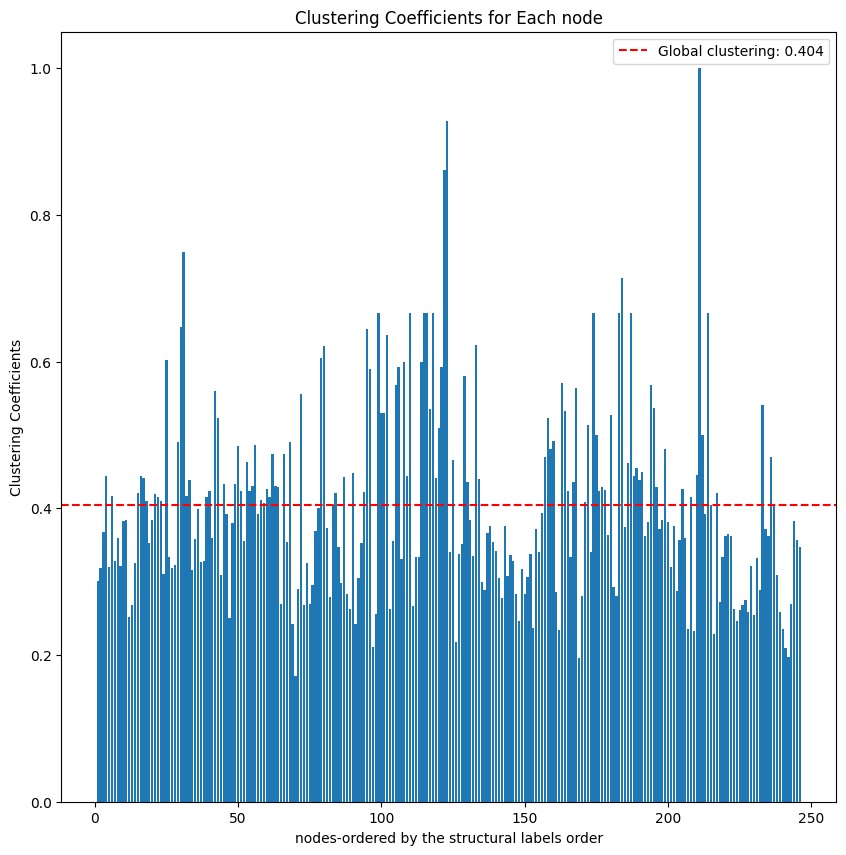

In [8]:
# plot the clustering coefficients

clusters_coeffs = []

for i in range(246):
    # Get column label for node i
    col_label = df.columns[i]

    # Neighbors of node i
    neighbors = df[col_label].index[df[col_label] > 0]

    if len(neighbors) < 2:
        # Not enough neighbors to form triangles
        clusters_coeffs.append(0.0)
        continue

    # Total possible pairs between neighbors
    total_pairs = len(neighbors) * (len(neighbors) - 1) / 2

    # Neighbor-only submatrix
    neighbor_idx = df.columns.get_indexer(neighbors)
    submatrix = df.iloc[neighbor_idx, neighbor_idx].values

    # Upper triangle values (unique neighbor-neighbor pairs)
    upper_vals = submatrix[np.triu_indices_from(submatrix, k=1)]

    # Classical (binary) clustering
    num_existing_pairs = np.sum(upper_vals > 0)
    C_classical = num_existing_pairs / total_pairs


    clusters_coeffs.append(float(C_classical))

#now calculating the clusterinf coeff for the whole matrix
C_global = np.mean(clusters_coeffs)
print(C_global)

#plot all values with the matching labels  as bargraph

import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
plt.bar(labels, clusters_coeffs)
plt.xlabel('nodes-ordered by the structural labels order')
plt.axhline(C_global, color='red', linestyle='--', label=f'Global clustering: {C_global:.3f}')
plt.ylabel('Clustering Coefficients')
plt.title('Clustering Coefficients for Each node')
#add legend
plt.legend()
plt.show()


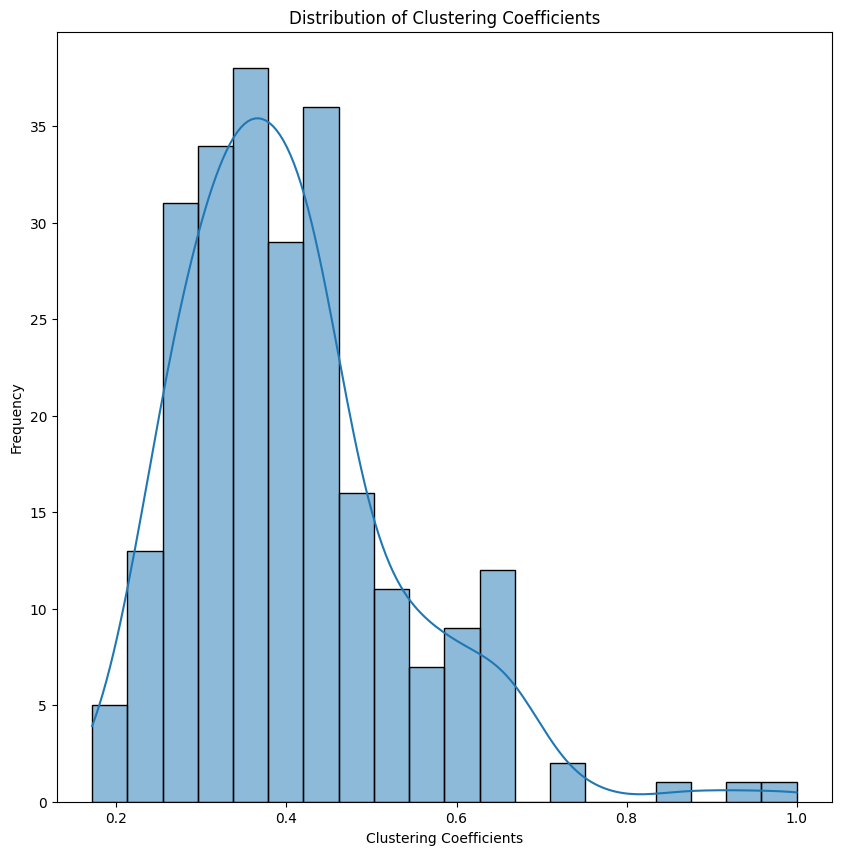

In [9]:
#also plotting  disttribution of the clustering coefficients
plt.figure(figsize=(10,10))
sns.histplot(clusters_coeffs, bins=20, kde=True)
plt.xlabel('Clustering Coefficients')
plt.ylabel('Frequency')
plt.title('Distribution of Clustering Coefficients')
plt.show()

We will calculate the integration metric, which is the global efficiency (Since the local efficiency was calculated earlier).


In [10]:
# calculating global efficency for the whole matrix

# Build graph from adjacency matrix (df)
G = nx.from_numpy_array(df.values)

# Ensure df is a NumPy array
weights = df.values

# Replace 0s and negatives with np.inf to avoid division by zero
# and signal no connection (used in inverse matrix for efficiency)
safe_weights = np.where(weights > 0, weights, np.inf)

# Compute inverse matrix
inv_mat = np.where(safe_weights != np.inf, 1 / safe_weights, 0)

# --- Global efficiency using NetworkX ---
inv_G = nx.from_numpy_array(inv_mat)

E_global_inv = nx.global_efficiency(inv_G)
E_global_bct = bct.efficiency_wei(inv_mat)
print("Global Efficiency (NetworkX):", E_global_inv)
print("Global Efficiency (BCT):", E_global_bct)

# Manual global efficiency
lengths = dict(nx.all_pairs_dijkstra_path_length(G, weight='weight'))
N = len(G)
efficiencies = []
for i in range(N):
    for j in range(N):
        if i != j:
            if j in lengths[i]:
                l_ij = lengths[i][j]
                e_ij = 1 / l_ij
            else:
                e_ij = 0
            efficiencies.append(e_ij)
E_global_manual = np.mean(efficiencies)
print("Global Efficiency (manual):", E_global_manual)

Global Efficiency (NetworkX): 0.48038272219440326
Global Efficiency (BCT): 0.3491965651920853
Global Efficiency (manual): 0.34919656519208525


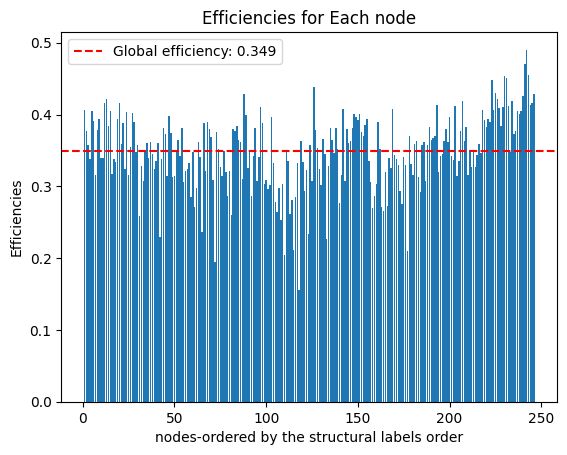

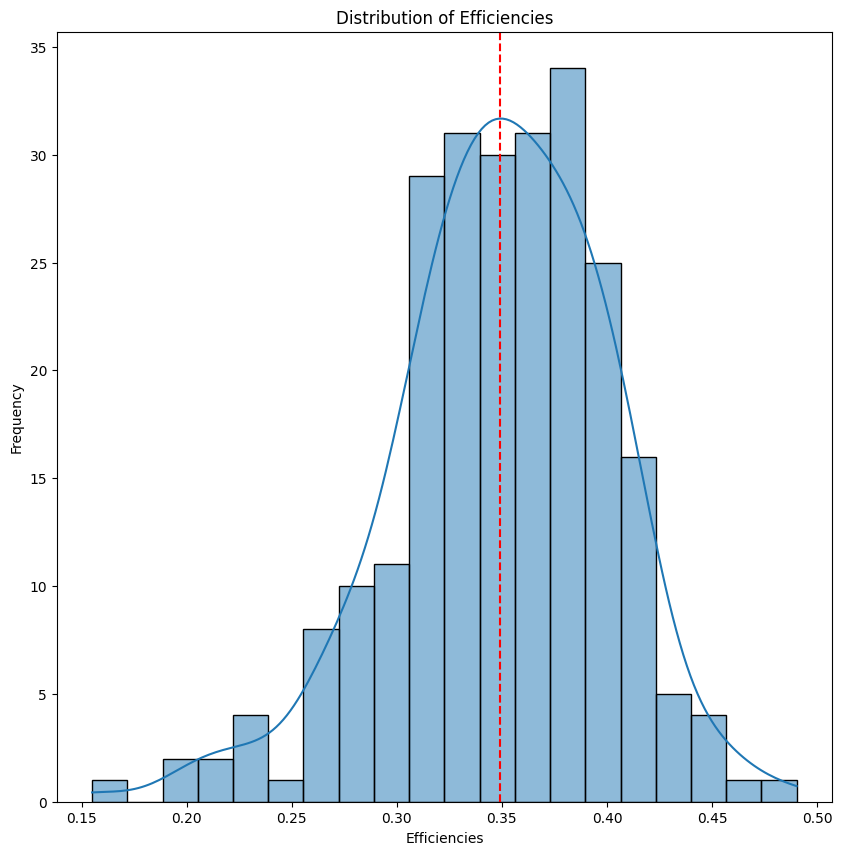

In [11]:
# Calculate global efficiency foe every nore and plot metric distribution

# Get all pairwise shortest paths
lengths = dict(nx.all_pairs_dijkstra_path_length(G))

# Extract all pairwise efficiencies (1 / l_ij)
N = len(G)
efficiencies = []
for i in range(N):
    for j in range(N):
        if i != j:
            if j in lengths[i]:
                l_ij = lengths[i][j]
                e_ij = 1 / l_ij
            else:
                e_ij = 0  # no path, efficiency = 0
            efficiencies.append(e_ij)

# Compute global efficiency as mean of pairwise efficiencies
E_global = np.mean(efficiencies)

nodal_efficiencies = []
for i in range(N):
    e_i = []
    for j in range(N):
        if i != j:
            if j in lengths[i]:
                l_ij = lengths[i][j]
                e_ij = 1 / l_ij
            else:
                e_ij = 0
            e_i.append(e_ij)
    E_i = np.mean(e_i)
    nodal_efficiencies.append(E_i)

E_global = np.mean(nodal_efficiencies)

#plot bargraph
plt.bar(labels, nodal_efficiencies)
plt.xlabel('nodes-ordered by the structural labels order')
plt.axhline(E_global, color='red', linestyle='--', label=f'Global efficiency: {E_global:.3f}')
plt.ylabel('Efficiencies')
plt.title('Efficiencies for Each node')
#add legend
plt.legend()
plt.show()

#plot sns histplot
plt.figure(figsize=(10, 10))
sns.histplot(nodal_efficiencies, bins=20, kde=True)
#add line for the global efficiency
plt.axvline(E_global, color='red', linestyle='--', label=f'Global Efficiency: {E_global:.3f}')
plt.xlabel('Efficiencies')
plt.ylabel('Frequency')
plt.title('Distribution of Efficiencies')
plt.show()

# Question 5

[(228, 912), (227, 868), (204, 738), (203, 598), (206, 558), (138, 555), (143, 537), (207, 527), (205, 522), (197, 512), (199, 505), (144, 478), (139, 461), (24, 457), (7, 443), (161, 437), (200, 432), (140, 430), (107, 429), (159, 419), (229, 391), (156, 383), (17, 382), (208, 380), (193, 378), (136, 375), (155, 374), (230, 373), (53, 371), (2, 367), (135, 365), (63, 360), (137, 360), (23, 359), (191, 354), (202, 354), (198, 351), (15, 328), (145, 328), (16, 316), (126, 312), (192, 307), (105, 306), (85, 303), (3, 301), (18, 300), (26, 300), (10, 299), (210, 297), (162, 294), (201, 291), (129, 287), (128, 286), (142, 284), (1, 281), (240, 279), (67, 278), (106, 278), (12, 277), (76, 276), (146, 275), (5, 272), (97, 268), (9, 263), (134, 262), (75, 258), (196, 251), (152, 250), (88, 244), (86, 243), (141, 240), (60, 235), (132, 234), (68, 233), (127, 232), (6, 232), (133, 227), (11, 226), (195, 226), (157, 224), (245, 222), (39, 219), (58, 216), (73, 214), (59, 212), (158, 212), (104, 

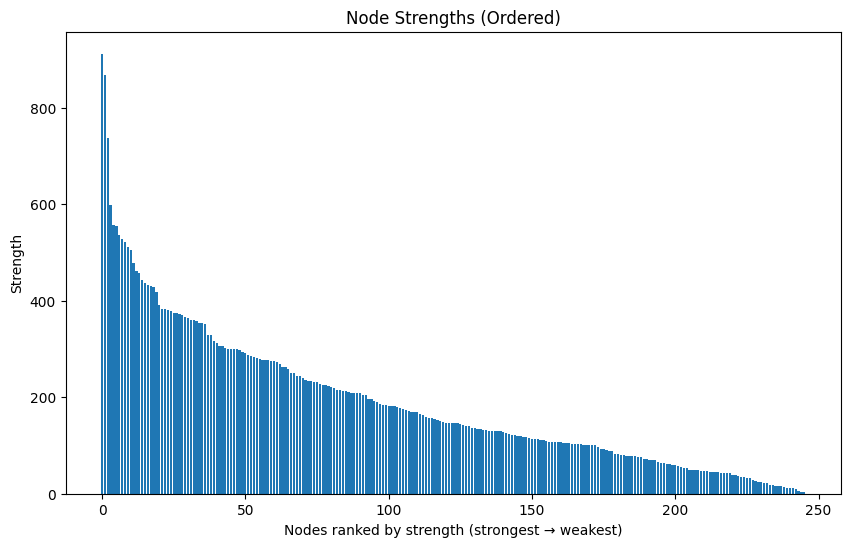

In [12]:
#calculate centrality for each node
strengths = bct.strengths_und(df.values)
#create a  list of tuple with label and strength:
#before -change each value ti int
labels = labels.astype(int)
strengths = strengths.astype(int)
lis_tuple = [(int(label), int(strength)) for label, strength in zip(labels, strengths)]

#sort the list by strength
lis_tuple=sorted(lis_tuple, key=lambda x: x[1], reverse=True)
print(lis_tuple)
#plot bar plot

#plot from highest to lowest# Plot with x-axis = rank (1 = strongest, 2 = second strongest…)
plt.figure(figsize=(10, 6))
plt.bar(range(len(lis_tuple)), [x[1] for x in lis_tuple])
plt.xlabel('Nodes ranked by strength (strongest → weakest)')
plt.ylabel('Strength')
plt.title('Node Strengths (Ordered)')
plt.show()


Connectivity matrix shape after node removal: (245, 245)


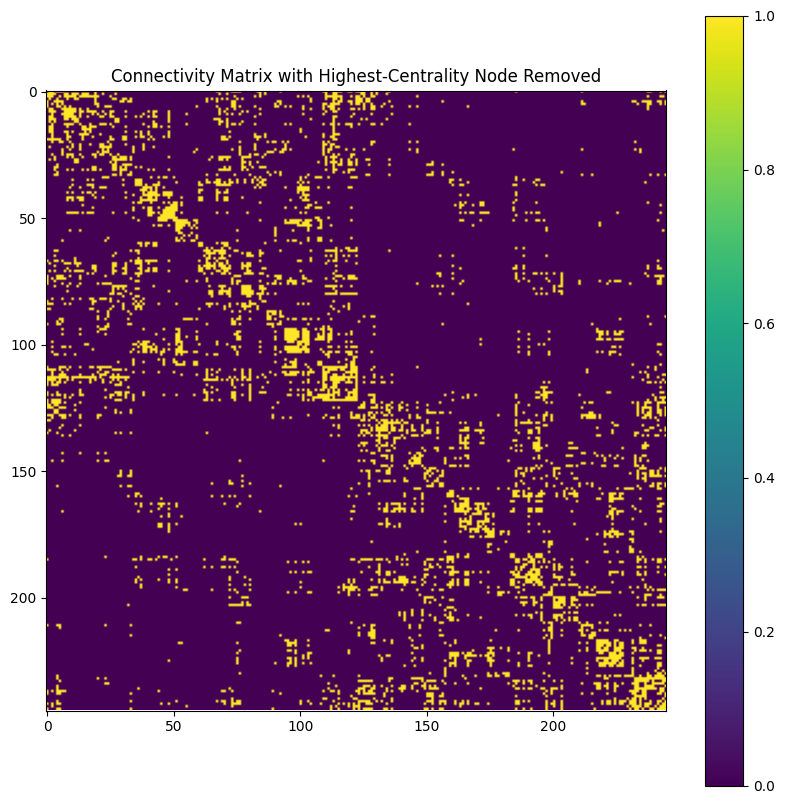

In [13]:
#now remove the node withthe highest strength
#first sort the list by strength
lis_tuple=sorted(lis_tuple, key=lambda x: x[1], reverse=True)
#gets its label
label_to_remove = lis_tuple[0][0]
#remove from the matrix
df_Mremoval = df.drop(label_to_remove, axis=0)
df_Mremoval_N = df_Mremoval.drop(label_to_remove, axis=1)
df_Mremoval=df_Mremoval_N
print(f'Connectivity matrix shape after node removal: {df_Mremoval.shape}')
#now plotting the heatmap
plt.figure(figsize=(10, 10))
plt.imshow(df_Mremoval>0)
plt.colorbar()
plt.title('Connectivity Matrix with Highest-Centrality Node Removed')
plt.show()

0.4018345082928364


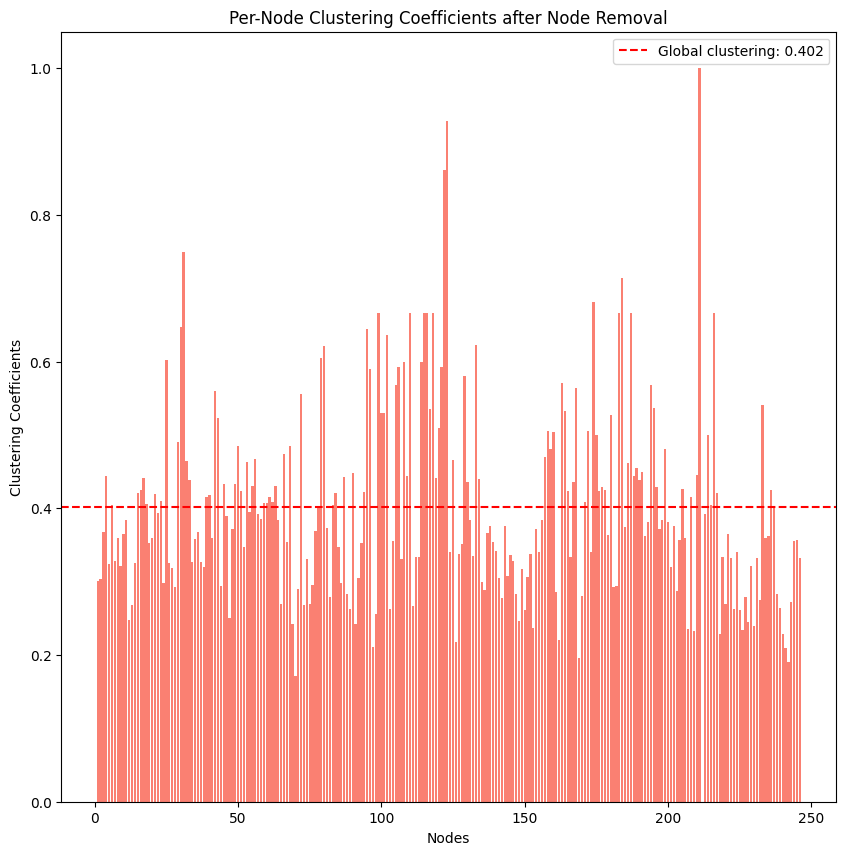

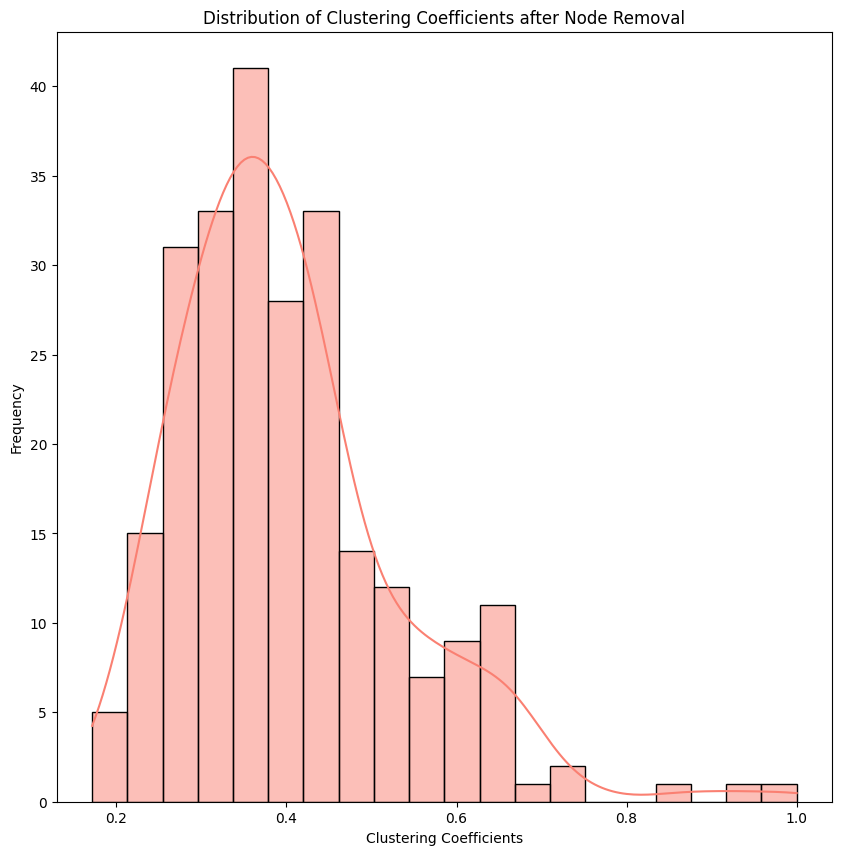

In [14]:
struct_label_copy = np.delete(labels, label_to_remove)

#now calculating clustering coefficents as before
clusters_coeffs_M = []

for i in range(245):
    # Get column label for node i
    col_label = df_Mremoval.columns[i]

    # Neighbors of node i
    neighbors = df_Mremoval[col_label].index[df_Mremoval[col_label] > 0]

    if len(neighbors) < 2:
        # Not enough neighbors to form triangles
        clusters_coeffs_M.append(0.0)
        continue

    # Total possible pairs between neighbors
    total_pairs = len(neighbors) * (len(neighbors) - 1) / 2

    # Neighbor-only submatrix
    neighbor_idx = df_Mremoval.columns.get_indexer(neighbors)
    submatrix = df_Mremoval.iloc[neighbor_idx, neighbor_idx].values

    # Upper triangle values (unique neighbor-neighbor pairs)
    upper_vals = submatrix[np.triu_indices_from(submatrix, k=1)]

    # Classical (binary) clustering
    num_existing_pairs = np.sum(upper_vals > 0)
    C_classical = num_existing_pairs / total_pairs
    clusters_coeffs_M.append(float(C_classical))

#now calculating the clusterinf coeff for the whole matrix
C_global_M = np.mean(clusters_coeffs_M)
print(C_global_M)

plt.figure(figsize=(10,10))
plt.bar(struct_label_copy, clusters_coeffs_M, color='salmon')
#calculate the mean
mean_value_Coeff = np.mean(clusters_coeffs_M)
plt.axhline(mean_value_Coeff, color='red', linestyle='--', label=f'Global clustering: {mean_value_Coeff:.3f}')
plt.ylabel('Clustering Coefficients')
plt.xlabel('Nodes')
plt.title('Per-Node Clustering Coefficients after Node Removal')
#add legend
plt.legend()
plt.show()

# plot the distribution
plt.figure(figsize=(10, 10))
sns.histplot(clusters_coeffs_M, bins=20, kde=True, color='salmon')
plt.xlabel('Clustering Coefficients')
plt.ylabel('Frequency')
plt.title('Distribution of Clustering Coefficients after Node Removal')
plt.show()

In [15]:
# Ensure df_Mremoval is a NumPy array
weights = df_Mremoval.values

# Replace 0s and negatives with np.inf to avoid division by zero
# and signal no connection (used in inverse matrix for efficiency)
safe_weights = np.where(weights > 0, weights, np.inf)

# Compute inverse matrix
inv_mat_M = np.where(safe_weights != np.inf, 1 / safe_weights, 0)

# --- Global efficiency using NetworkX ---
inv_G_M = nx.from_numpy_array(inv_mat_M)
E_global_inv_M = nx.global_efficiency(inv_G_M)
print("Global Efficiency after removal (NetworkX):", E_global_inv_M)

# --- Global efficiency using BCT ---
E_global_bct_M = bct.efficiency_wei(inv_mat_M)
print("Global Efficiency after removal (BCT):", E_global_bct_M)

# --- Manual computation of global efficiency ---
G_M = nx.from_numpy_array(weights)
lengths = dict(nx.all_pairs_dijkstra_path_length(G_M, weight='weight'))
N = len(G_M)

nodal_efficiencies = []
for i in range(N):
    e_i = []
    for j in range(N):
        if i != j:
            l_ij = lengths[i].get(j, np.inf)
            if l_ij > 0 and np.isfinite(l_ij):
                e_ij = 1 / l_ij
            else:
                e_ij = 0
            e_i.append(e_ij)
    E_i = np.mean(e_i) if e_i else 0
    nodal_efficiencies.append(E_i)

E_global_M = np.mean(nodal_efficiencies)
print("Global Efficiency after removal (manual):", E_global_M)


Global Efficiency after removal (NetworkX): 0.47858815657393844
Global Efficiency after removal (BCT): 0.3486734826639477
Global Efficiency after removal (manual): 0.34867348266394765


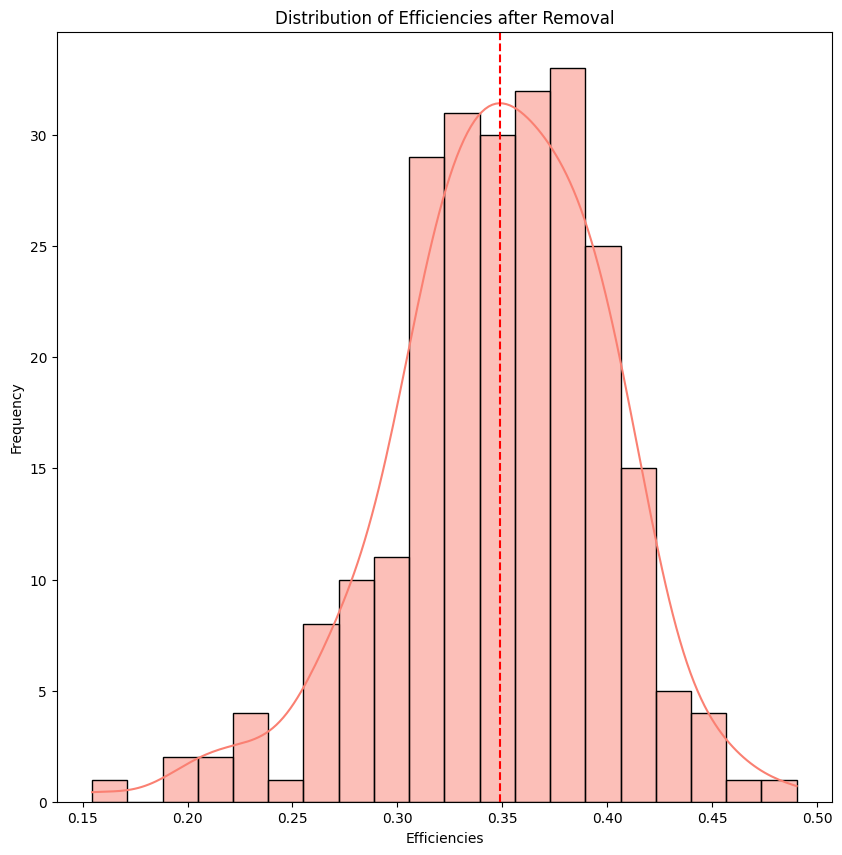

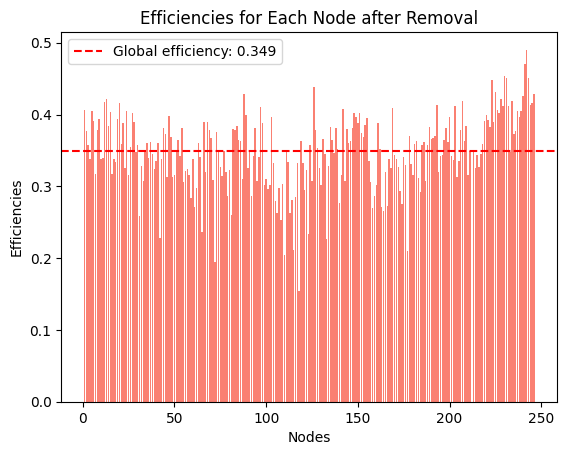

In [16]:
#plot sns hist
plt.figure(figsize=(10, 10))
sns.histplot(nodal_efficiencies, bins=20, kde=True, color='salmon')
#add global efficiency
plt.axvline(E_global_M, color='red', linestyle='--', label=f'Global Efficiency: {E_global_M:.3f}')
plt.xlabel('Efficiencies')
plt.ylabel('Frequency')
plt.title('Distribution of Efficiencies after Removal')
plt.show()
#plot bar
plt.bar(struct_label_copy, nodal_efficiencies, color='salmon')
plt.xlabel('Nodes')
plt.axhline(E_global_M, color='red', linestyle='--', label=f'Global efficiency: {E_global_M:.3f}')
plt.ylabel('Efficiencies')
plt.title('Efficiencies for Each Node after Removal')
#add legend
plt.legend()
plt.show()

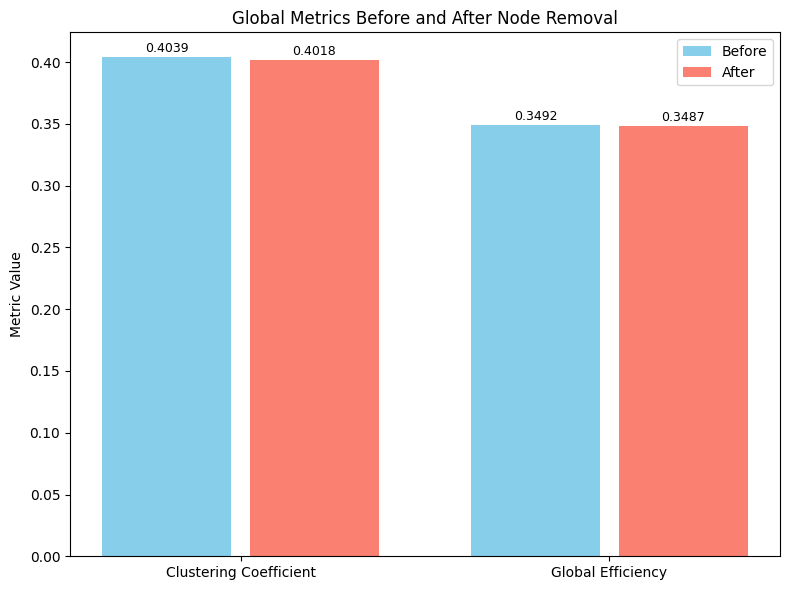

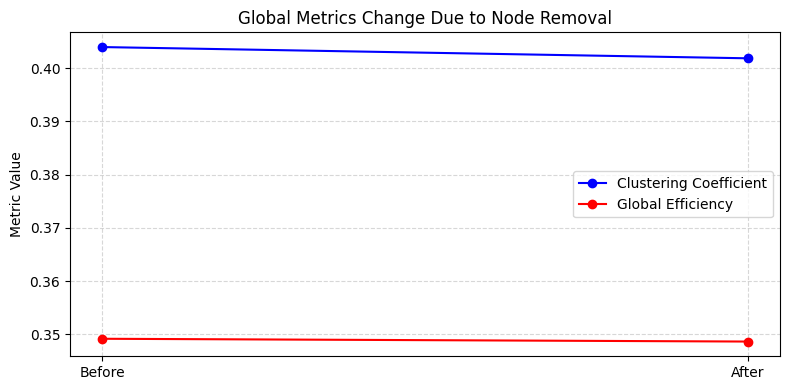

In [17]:
# Data setup
metrics = ['Clustering Coefficient', 'Global Efficiency']
before_values = [C_global, E_global]
after_values = [C_global_M, E_global_M]

x = np.arange(len(metrics))  # [0, 1]
width = 0.35
gap = 0.05  # small gap between bars

# Shifted bar positions with gap
before_pos = x - width / 2 - gap / 2
after_pos  = x + width / 2 + gap / 2

# --- Side-by-side bar plot ---
fig, ax = plt.subplots(figsize=(8, 6))

bars1 = ax.bar(before_pos, before_values, width, label='Before', color='skyblue')
bars2 = ax.bar(after_pos, after_values, width, label='After', color='salmon')

# Labeling
ax.set_ylabel('Metric Value')
ax.set_title('Global Metrics Before and After Node Removal')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

# Annotate bar values
for bar in bars1 + bars2:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.03 * max(before_values + after_values), f'{yval:.4f}', ha='center', va='top', fontsize=9)

plt.tight_layout()
plt.show()

# --- Line plot showing metric changes ---
plt.figure(figsize=(8, 4))

# Clustering Coefficient change
plt.plot([0, 1], [C_global, C_global_M], 'bo-', label='Clustering Coefficient')

# Global Efficiency change
plt.plot([0, 1], [E_global, E_global_M], 'ro-', label='Global Efficiency')

plt.xticks([0, 1], ['Before', 'After'])
plt.ylabel('Metric Value')
plt.title('Global Metrics Change Due to Node Removal')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
